# Dask Delayed

__Автор задач: Блохин Н.В. (NVBlokhin@fa.ru)__

Материалы:
* Макрушин С.В. Лекция "Dask Delayed"
* https://docs.dask.org/en/latest/delayed.html
* Jesse C. Daniel. Data Science with Python and Dask.
* https://saturncloud.io/blog/a-data-scientist-s-guide-to-lazy-evaluation-with-dask/
* https://www.coiled.io/blog/how-to-learn-dask-in-2021
* https://realpython.com/python-concurrency/

In [138]:
!pip install gdown

INFO:distributed.core:Event loop was unresponsive in Nanny for 9.33s.  This is often caused by long-running GIL-holding functions or moving large chunks of data. This can cause timeouts and instability.
INFO:distributed.core:Event loop was unresponsive in Nanny for 9.34s.  This is often caused by long-running GIL-holding functions or moving large chunks of data. This can cause timeouts and instability.
INFO:distributed.core:Event loop was unresponsive in Nanny for 12.43s.  This is often caused by long-running GIL-holding functions or moving large chunks of data. This can cause timeouts and instability.
INFO:distributed.core:Event loop was unresponsive in Scheduler for 17.23s.  This is often caused by long-running GIL-holding functions or moving large chunks of data. This can cause timeouts and instability.
INFO:distributed.core:Event loop was unresponsive in Scheduler for 9.34s.  This is often caused by long-running GIL-holding functions or moving large chunks of data. This can cause t

In [1]:
import gdown
import zipfile
import os
import glob

import dask
import dask.bag as db
import dask.array as da
import dask.dataframe as dd
import dask.delayed as delayed
from dask.diagnostics import ProgressBar

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

from time import sleep
from time import time
import random

import xml.etree.ElementTree as ET

In [140]:
#https://drive.google.com/file/d/1Go_IDvX63IdvtD5EBSLgfmO1_xSpEv_5/view?usp=sharing

zip_file_path = 'reviewers_full.zip'
gdown.download(id='1Go_IDvX63IdvtD5EBSLgfmO1_xSpEv_5', output= zip_file_path, quiet=False)


Downloading...
From (original): https://drive.google.com/uc?id=1Go_IDvX63IdvtD5EBSLgfmO1_xSpEv_5
From (redirected): https://drive.google.com/uc?id=1Go_IDvX63IdvtD5EBSLgfmO1_xSpEv_5&confirm=t&uuid=028ce74b-5500-40c4-838e-dfc56307f58a
To: /content/reviewers_full.zip
100%|██████████| 31.0M/31.0M [00:00<00:00, 44.0MB/s]


In [3]:
zip_file_path = 'reviewers_full.zip'
extract_to_dir = 'reviewers_full'
if not os.path.exists(extract_to_dir):
    os.makedirs(extract_to_dir)
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_dir)

In [141]:
#reviewers_full/reviewers_full

## Задачи для совместного разбора

1\. Напишите 2 функции, имитирующие CPU-bound задачу и IO-bound задачу:

`cpu_task()`: генерирует 100 тыс. случайных чисел и возвращает их сумму (без использования `numpy`)

`io_task()`: "спит" 0.1 сек, затем генерирует случайное число и возвращает его

Замерьте время выполнения 100 последовательных вызовов каждой из этих функций. Распараллелив вычисления при помощи `dask.delayed`, сократите время выполнения. Исследуйте, как зависит время вычислений от выбранного планировщика `scheduler`.

In [4]:
def cpu_task():
  sums=0
  for i in range(100_000):
    sums+=random.random()
  return sums

def io_task():
  sleep(0.1)
  return random.random()

#Замерьте время выполнения 100 последовательных вызовов каждой из этих функций.
print(f'Без распараллеливания')
t1=time()
for i in range(100):
  cpu_task()
print(time()-t1)

t1=time()
for i in range(100):
  io_task()
print(time()-t1)

Без распараллеливания
0.4969637393951416
10.056825160980225


In [5]:
#Распараллелив вычисления при помощи dask.delayed, сократите время выполнения.
out=[]
for i in range(100):
  out.append(dask.delayed(cpu_task)())
t1=time()
dask.compute(out)
print(time()-t1)

out=[]
for i in range(100):
  out.append(dask.delayed(io_task)())
t1=time()
dask.compute(out)
print(time()-t1)

0.9007618427276611
0.7309854030609131


In [6]:
#Исследуйте, как зависит время вычислений от выбранного планировщика scheduler.

schedulers = ['threads','processes','single-threaded']
#threads         <=> многопоточный
#processes       <=> многопроцессорный
#single-threaded <=> однопоточный
for scheduler in schedulers:
  print(scheduler)
  out=[]
  for i in range(100):
    out.append(dask.delayed(cpu_task)())
  t1=time()
  dask.compute(out, scheduler=scheduler)
  print(time()-t1)

  out=[]
  for i in range(100):
    out.append(dask.delayed(io_task)())
  t1=time()
  dask.compute(out, scheduler=scheduler)
  print(time()-t1)

threads
0.9001801013946533
0.7233879566192627
processes
1.297966480255127
2.0004138946533203
single-threaded
0.990431547164917
10.088380098342896


## Лабораторная работа 14

<p class="task" id="1"></p>

### 1\. Напишите функцию `read_profiles`, которая считывает один файл формата xml из каталога `reviewers_full` и по данным этого файла формирует список словарей, содержащих следующие ключи: `id`, `username`, `name`, `sex`, `country`, `mail`, `registered`, `birthdate`, `name_prefix`, `country_code`. Часть из этих значений в исходном файле хранится в виде тэгов, часть - в виде атрибутов тэгов. Для конкретного человека какие-то из этих ключей могут отсутствовать.

Обработайте все файлы, последовательно вызвая эту функцию для каждого из них, и собрав результаты в один общий список словарей `profiles`. Измерьте время выполнения кода.

Выведите на экран уникальные значения по ключам `name_prefix` и `country_code`


```python
def read_profiles(file: str) -> list[dict]:
    pass
```

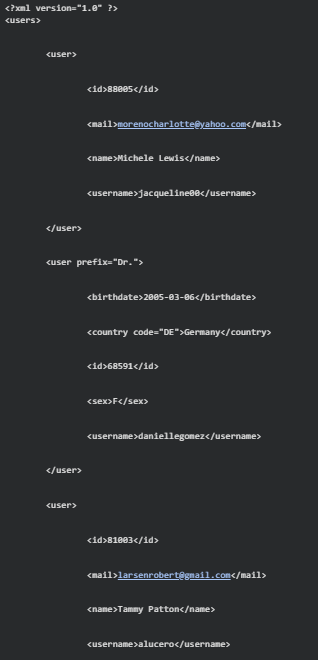

In [11]:
filepath = 'reviewers_full/reviewers_full/reviewers_full_0.xml'

if filepath:
    tree = ET.parse(filepath)
    root = tree.getroot()

    all_tags = set()
    all_attrs = set()

    for user in root.findall('user'):
        for element in user.iter():
            all_tags.add(element.tag)
            for attr_name in element.keys():
                all_attrs.add(attr_name)

    print("теги")
    print(sorted(list(all_tags)))

    print("атрибуты")
    print(sorted(list(all_attrs)))

теги
['birthdate', 'country', 'id', 'mail', 'name', 'registered', 'sex', 'user', 'username']
атрибуты
['code', 'prefix']


In [25]:
tag_to_attrs = defaultdict(set)
all_tags = set()

filepath = 'reviewers_full/reviewers_full/reviewers_full_0.xml'


tree = ET.parse(filepath)
root = tree.getroot()

for user in root.findall('user'):
    for element in user.iter():
        tag_name = element.tag
        all_tags.add(tag_name)

        attrs = element.keys()
        if attrs:
            tag_to_attrs[tag_name].update(attrs)

print("теги")
print(sorted(list(all_tags)))

print("атрибуты")
if not tag_to_attrs:
    print("нету")
else:
    for tag, attrs in sorted(tag_to_attrs.items()):
        print(f"тег <{tag}> имеет атрибуты: {sorted(list(attrs))}")

теги
['birthdate', 'country', 'id', 'mail', 'name', 'registered', 'sex', 'user', 'username']
атрибуты
тег <country> имеет атрибуты: ['code']
тег <user> имеет атрибуты: ['prefix']


In [28]:
#Напишите функцию read_profiles, которая считывает один файл формата xml из каталога reviewers_full
def read_profiles(filepath):
  tree = ET.parse(filepath)
  root = tree.getroot()
  keys_simple=  'id, username, sex, mail, registered, birthdate, name'.split(', ')

  out=[]
  for user in root.findall('user'):
    #по данным этого файла формирует список словарей, содержащих следующие ключи: id, username, name, sex, country, mail, registered, birthdate, name_prefix, country_code.
    d=dict()
    for k in keys_simple:
      res = user.find(f'.//{k}');
      if res is not None: res=res.text
      else: res=user.get(k)
      d.update({k:res})

    name_ = user.find('.//prefix')
    if name_ is not None:name_=name_.text
    else: name_=user.get('prefix')
    d.update({'name_prefix':name_})

    country_ = user.find('.//country')
    if country_ is not None:
        d['country']      = country_.text
        d['country_code'] = country_.get('code')
    else:
        d['country'] = None
        d['country_code'] = None
    out.append(d)

  return out
rev_0 = read_profiles('reviewers_full/reviewers_full/reviewers_full_0.xml')
display(rev_0[0])

#общий список словарей profiles
#'''
t1=time()
profiles = [profile for filepath in os.listdir('reviewers_full/reviewers_full') for profile in read_profiles(f'reviewers_full/reviewers_full/{filepath}')]
print(f'\n\nВРЕМЯ ВЫПОЛНЕНИЯ: {time()-t1:.4f}\n\n')#Измерьте время выполнения кода.
#'''
"""
t1=time()
profiles = []
for filepath in os.listdir('reviewers_full/reviewers_full'):
  profiles.append(dask.delayed(read_profiles)(f'reviewers_full/reviewers_full/{filepath}'))
with ProgressBar():
  profiles=[pr for p in dask.compute(profiles,scheduler='processes')[0]for pr in p]
print(time()-t1)#Измерьте время выполнения кода.
"""
#Выведите на экран уникальные значения по ключам name_prefix и country_code
unique_prefixes = {p.get("name_prefix") for p in profiles if p.get("name_prefix")}
unique_codes = {p.get("country_code") for p in profiles if p.get("country_code")}
prefixes_str = "\n".join(sorted(list(unique_prefixes)))
codes_str = "\n".join(sorted(list(unique_codes)))

print(f'name_prefix:\n{prefixes_str}')
print(f'\ncountry_code:\n{codes_str}')

{'id': '88005',
 'username': 'jacqueline00',
 'sex': None,
 'mail': 'morenocharlotte@yahoo.com',
 'registered': None,
 'birthdate': None,
 'name': 'Michele Lewis',
 'name_prefix': None,
 'country': None,
 'country_code': None}



ВРЕМЯ ВЫПОЛНЕНИЯ: 41.2196


name_prefix:
Dr.
Miss
Mr.
Mrs.
Ms.

country_code:
AD
AE
AF
AG
AI
AL
AM
AN
AO
AR
AS
AT
AU
AW
AZ
BA
BB
BD
BE
BF
BG
BH
BI
BJ
BM
BN
BO
BR
BS
BT
BW
BY
BZ
CA
CC
CF
CH
CK
CL
CM
CN
CO
CR
CU
CV
CX
CY
CZ
DE
DJ
DK
DM
DO
DZ
EC
EE
EG
EH
ER
ES
ET
FI
FJ
FK
FO
FR
GA
GB
GD
GE
GF
GG
GH
GI
GL
GM
GN
GP
GQ
GR
GS
GT
GU
GW
GY
HM
HN
HR
HT
HU
ID
IE
IL
IM
IN
IQ
IR
IS
IT
JE
JM
JO
JP
KE
KH
KI
KM
KN
KW
KY
KZ
LA
LB
LC
LI
LK
LR
LS
LT
LU
LV
LY
MA
MC
ME
MF
MG
MH
ML
MM
MN
MO
MP
MQ
MR
MS
MT
MU
MV
MW
MX
MY
MZ
NC
NE
NF
NG
NI
NL
NO
NP
NR
NU
NZ
OM
PA
PE
PF
PG
PH
PK
PL
PM
PR
PT
PW
PY
QA
RE
RO
RS
RW
SA
SB
SC
SD
SE
SG
SI
SL
SM
SN
SO
SR
ST
SV
SY
SZ
TD
TF
TG
TH
TJ
TK
TL
TM
TN
TO
TR
TT
TV
TW
TZ
UA
UG
UM
UY
UZ
VA
VC
VE
VN
VU
WF
WS
YE
YT
ZA
ZM
ZW
nan


In [148]:
profiles[4]

{'id': '74667',
 'username': 'wesley96',
 'sex': None,
 'mail': None,
 'registered': '2006-12-29',
 'birthdate': None,
 'name': None,
 'name_prefix': None,
 'country': None,
 'country_code': None}

<p class="task" id="2"></p>

### 2\. Задекорируйте функцию `read_profiles` при помощи `dask.delayed`. Cоздайте список `reviewers`, состоящий из 20 объектов `Delayed` (по одному объекту на файл). Повторите решение задачи 1, распараллелив вычисления при помощи `dask`. Измерьте время выполнения кода. Добейтесь существенного (в разы) уменьшения времени выполнения в сравнении с решением задачи 1.

In [29]:
@dask.delayed #Задекорируйте функцию read_profiles при помощи dask.delayed
def read_profiles(filepath):
  tree = ET.parse(filepath)
  root = tree.getroot()
  keys_simple=  'id, username, sex, mail, registered, birthdate, name'.split(', ')

  out=[]
  for user in root.findall('user'):
    #по данным этого файла формирует список словарей, содержащих следующие ключи: id, username, name, sex, country, mail, registered, birthdate, name_prefix, country_code.
    d=dict()
    for k in keys_simple:
      res = user.find(f'.//{k}');
      if res is not None: res=res.text
      else: res=user.get(k)
      d.update({k:res})

    name_ = user.find('.//prefix')
    if name_ is not None:name_=name_.text
    else: name_=user.get('prefix')
    d.update({'name_prefix':name_})

    country_ = user.find('.//country')
    if country_ is not None:
        d['country']      = country_.text
        d['country_code'] = country_.get('code')
    else:
        d['country'] = None
        d['country_code'] = None
    out.append(d)

  return out

t1=time()
reviewers=[read_profiles(f'reviewers_full/reviewers_full/{filepath}')for filepath in os.listdir('reviewers_full/reviewers_full')] #Cоздайте список reviewers, состоящий из 20 объектов Delayed
with ProgressBar():
  reviewers=dask.compute(reviewers,scheduler='processes')[0]
print(f'\n\nВРЕМЯ ВЫПОЛНЕНИЯ: {time()-t1:.4f}\n\n')#Измерьте время выполнения кода.
print(len(reviewers))

[########################################] | 100% Completed | 11.82 s


ВРЕМЯ ВЫПОЛНЕНИЯ: 11.8888


20


<p class="task" id="3"></p>

### 3\. Задекорируйте функцию из задания 1 при помощи `dask.delayed` и создайте список `reviewers`, состоящий из 20 объектов `Delayed` (по одному объекту на файл). Из списка объектов `Delayed`, создайте `dask.bag` при помощи метода `db.from_delayed`. Добавьте ключ `birth_year`, в котором хранится год рождения человека. Оставьте в выборке только тех людей, которые __наверняка__ моложе 1980 года. Преобразуйте поле `id` к целому типу.

Выведите на экран количество элементов в созданном `Bag`.

In [30]:
@dask.delayed #Задекорируйте функцию read_profiles при помощи dask.delayed
def read_profiles(filepath):
  tree = ET.parse(filepath)
  root = tree.getroot()
  keys_simple=  'id, username, sex, mail, registered, birthdate, name'.split(', ')

  out=[]
  for user in root.findall('user'):
    #по данным этого файла формирует список словарей, содержащих следующие ключи: id, username, name, sex, country, mail, registered, birthdate, name_prefix, country_code.
    d=dict()
    for k in keys_simple:
      res = user.find(f'.//{k}');
      if res is not None: res=res.text
      else: res=user.get(k)
      d.update({k:res})

    name_ = user.find('.//prefix')
    if name_ is not None:name_=name_.text
    else: name_=user.get('prefix')
    d.update({'name_prefix':name_})

    country_ = user.find('.//country')
    if country_ is not None:
        d['country']      = country_.text
        d['country_code'] = country_.get('code')
    else:
        d['country'] = None
        d['country_code'] = None
    out.append(d)

  return out

t1=time()
reviewers=[read_profiles(f'reviewers_full/reviewers_full/{filepath}')for filepath in os.listdir('reviewers_full/reviewers_full')] #Cоздайте список reviewers, состоящий из 20 объектов Delayed
rev_db = db.from_delayed(reviewers) #создайте dask.bag при помощи метода db.from_delayed

#Добавьте ключ birth_year, в котором хранится год рождения человека.
bd_get = lambda p: {**p, 'birth_year':p.get('birthdate')[:4] if p.get('birthdate') is not None else None}

# Оставьте в выборке только тех людей, которые наверняка моложе 1980 года
young_filter = lambda p: int(p.get('birth_year'))>1980 if p.get('birth_year') is not None else False

#Преобразуйте поле id к целому типу.
id_get = lambda p: {**p, 'id':int(p.get('id')) if p.get('id') is not None else None}

rev_db = rev_db.map(bd_get)
rev_db = rev_db.filter(young_filter)
rev_db = rev_db.map(id_get)

counter = rev_db.count()

with ProgressBar():
  #Выведите на экран количество элементов в созданном Bag.
  reviewers,counter=dask.compute(rev_db,counter,scheduler='processes')
  print(reviewers[0])

print('количество элементов в созданном Bag:',counter)
print(f'\n\nВРЕМЯ ВЫПОЛНЕНИЯ: {time()-t1:.4f}\n\n')#Измерьте время выполнения кода.

[                                        ] | 0% Completed | 1.57 ms

[########################################] | 100% Completed | 16.01 s
{'id': 68591, 'username': 'daniellegomez', 'sex': 'F', 'mail': None, 'registered': None, 'birthdate': '2005-03-06', 'name': None, 'name_prefix': 'Dr.', 'country': 'Germany', 'country_code': 'DE', 'birth_year': '2005'}
количество элементов в созданном Bag: 287501


ВРЕМЯ ВЫПОЛНЕНИЯ: 16.1529




<p class="task" id="4"></p>

### 4\. Преобразуйте `Bag` из предыдущего задания в `dd.DataFrame`. Найдите и выведите на экран страну с наибольшим количеством пользователей.

In [2]:
@dask.delayed #Задекорируйте функцию read_profiles при помощи dask.delayed
def read_profiles(filepath):
  tree = ET.parse(filepath)
  root = tree.getroot()
  keys_simple=  'id, username, sex, mail, registered, birthdate, name'.split(', ')

  out=[]
  for user in root.findall('user'):
    #по данным этого файла формирует список словарей, содержащих следующие ключи: id, username, name, sex, country, mail, registered, birthdate, name_prefix, country_code.
    d=dict()
    for k in keys_simple:
      res = user.find(f'.//{k}');
      if res is not None: res=res.text
      else: res=user.get(k)
      d.update({k:res})

    name_ = user.find('.//prefix')
    if name_ is not None:name_=name_.text
    else: name_=user.get('prefix')
    d.update({'name_prefix':name_})

    country_ = user.find('.//country')
    if country_ is not None:
        d['country']      = country_.text
        d['country_code'] = country_.get('code')
    else:
        d['country'] = None
        d['country_code'] = None
    out.append(d)

  return out

t1=time()
reviewers=[read_profiles(f'reviewers_full/reviewers_full/{filepath}')for filepath in os.listdir('reviewers_full/reviewers_full')] #Cоздайте список reviewers, состоящий из 20 объектов Delayed
rev_db = db.from_delayed(reviewers) #создайте dask.bag при помощи метода db.from_delayed

#Добавьте ключ birth_year, в котором хранится год рождения человека.
bd_get = lambda p: {**p, 'birth_year':p.get('birthdate')[:4] if p.get('birthdate') is not None else None}

# Оставьте в выборке только тех людей, которые наверняка моложе 1980 года
young_filter = lambda p: int(p.get('birth_year'))>1980 if p.get('birth_year') is not None else False

#Преобразуйте поле id к целому типу.
id_get = lambda p: {**p, 'id':int(p.get('id')) if p.get('id') is not None else None}

rev_db = rev_db.map(bd_get)
rev_db = rev_db.filter(young_filter)
rev_db = rev_db.map(id_get)

meta = pd.DataFrame({
    'id':           pd.Series(dtype='int64' ),
    'username':     pd.Series(dtype='object'),
    'name':         pd.Series(dtype='object'),
    'sex':          pd.Series(dtype='object'),
    'country':      pd.Series(dtype='object'),
    'mail':         pd.Series(dtype='object'),
    'registered':   pd.Series(dtype='object'),
    'birthdate':    pd.Series(dtype='object'),
    'name_prefix':  pd.Series(dtype='object'),
    'country_code': pd.Series(dtype='object'),
    'birth_year':   pd.Series(dtype='int64' )
})

rev_dd = rev_db.to_dataframe(meta=meta)#Преобразуйте Bag из предыдущего задания в dd.DataFrame

#Найдите и выведите на экран страну с наибольшим количеством пользователей.
display(rev_dd.groupby('country')['id'].count().idxmax().compute(scheduler='processes'))

'Korea'

<p class="task" id="5"></p>

### 5\. Даны две функции: `get_product` и `add_to_db`. Воспользовавшись функцией `get_product`, получите список из 16 товаров с ID от 1 до 16. Добавьте каждый товар в БД __по отдельности__ при помощи функции `add_to_db`. Посчитайте общую сумму добавленных товаров и выведите ее на экран. Замерьте время выполнения данного решения.

При решении данной задачи не используйте параллельных вычислений (включая `dask`).

__Важно__: выполните ячейку ниже и далее работайте с запущенным `Client` (даже если вы его не используете, как в этой задаче).

In [5]:
# ЭТА ЯЧЕЙКА ЯВЛЯЕТСЯ ЧАСТЬЮ УСЛОВИЯ ЗАДАЧИ
# ИЗМЕНЯТЬ СОДЕРЖИМОЕ ЭТОЙ ЯЧЕЙКИ ЗАПРЕЩЕНО

import requests
from dask.distributed import Semaphore, Client
import time

client = Client()
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 4
Total threads: 16,Total memory: 31.29 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:59348,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:59368,Total threads: 4
Dashboard: http://127.0.0.1:59371/status,Memory: 7.82 GiB
Nanny: tcp://127.0.0.1:59351,


In [6]:
# ЭТА ЯЧЕЙКА ЯВЛЯЕТСЯ ЧАСТЬЮ УСЛОВИЯ ЗАДАЧИ
# ИЗМЕНЯТЬ СОДЕРЖИМОЕ ЭТОЙ ЯЧЕЙКИ ЗАПРЕЩЕНО

def get_product(pid: int) -> dict:
    """Делает запрос к dummyjson и возвращает информацию о товаре"""
    return requests.get(f"https://dummyjson.com/products/{pid}").json()

def estimate_fake_delay_time(n: int) -> float:
    """Возвращает кол-во секунд для задержки в зависимости от числа n"""
    return 0.07*n**2 -0.03*n + 2

sem = Semaphore(2)

def add_to_db(*products):
    """Принимает на вход переменное количество словарей (товаров), считает сумму и имитирует
    длительную операцию сохранения этих элементов в БД, время выполнения которой зависит от кол-ва переданных элементо.
    Одновременно могут обрабатываться только 2 запроса (это контролируется семафором)."""
    ttl = 0
    for p in products:
        print("Added {} to db".format(p["title"]))
        ttl += p["price"]
    with sem:
        time.sleep(estimate_fake_delay_time(len(products)))
    return ttl

In [40]:
t1=time.time()
prods = [get_product(pid) for pid in range(1,17)]
ttl = [add_to_db(prod) for prod in prods]
sums = sum(ttl)
print(f"Общая сумма: {sums}")
print(f'\n\nВРЕМЯ ВЫПОЛНЕНИЯ: {time.time()-t1:.4f}\n\n')#Измерьте время выполнения кода.

Added Essence Mascara Lash Princess to db
Added Eyeshadow Palette with Mirror to db
Added Powder Canister to db
Added Red Lipstick to db
Added Red Nail Polish to db
Added Calvin Klein CK One to db
Added Chanel Coco Noir Eau De to db
Added Dior J'adore to db
Added Dolce Shine Eau de to db
Added Gucci Bloom Eau de to db
Added Annibale Colombo Bed to db
Added Annibale Colombo Sofa to db
Added Bedside Table African Cherry to db
Added Knoll Saarinen Executive Conference Chair to db
Added Wooden Bathroom Sink With Mirror to db
Added Apple to db
Общая сумма: 6488.839999999998


ВРЕМЯ ВЫПОЛНЕНИЯ: 42.6699




<p class="task" id="6"></p>

### 6\. Создайте отложенные версии функций `get_product` и `add_to_db`. Постройте при помощи этих функций граф вычислений, который будет выглядеть следующим образом:

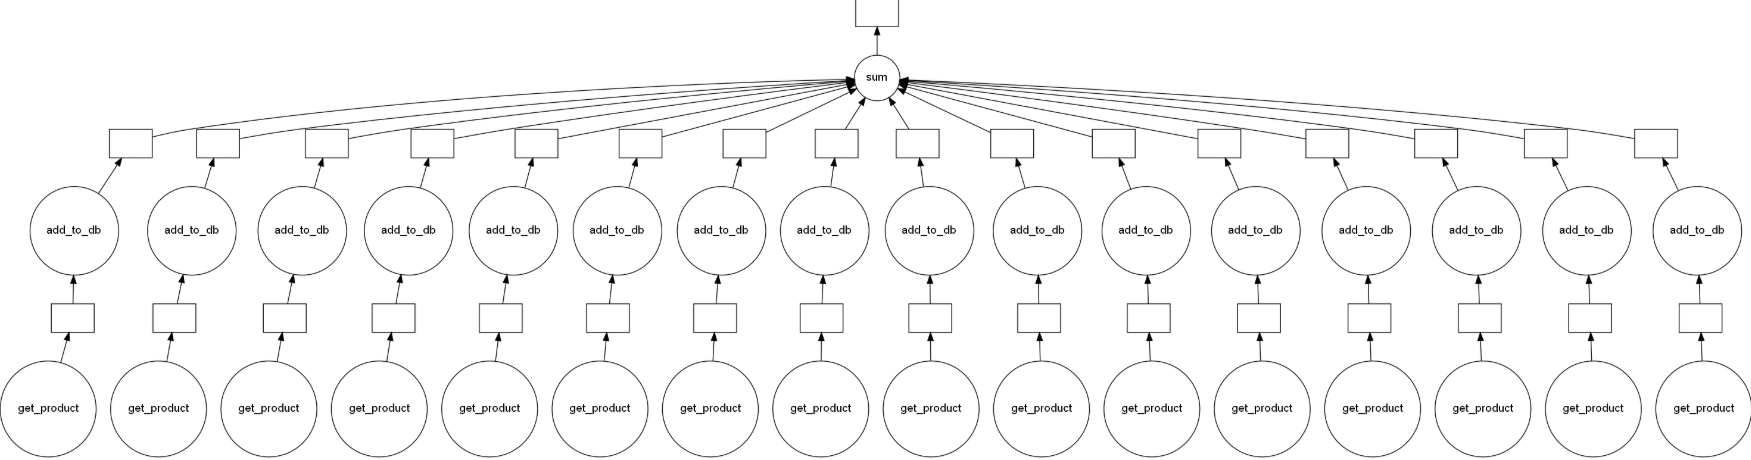

Здесь для каждого товара параллельно происходит вызов `get_product`, за которым следует вызов  `add_to_db`. Используя построенный граф, посчитайте общую сумму добавленных товаров и выведите ее на экран. Замерьте время выполнения данного решения.

В качестве демонстрации вставьте скриншот графа в процессе вычислений из дэшборда или результат работы метода `visualize`.

In [7]:
import time
t1=time.time()
#Создайте отложенные версии функций get_product и add_to_db
get_product_delayed = dask.delayed(get_product)
add_to_db_delayed = dask.delayed(add_to_db)

#Постройте при помощи этих функций граф вычислений, который будет выглядеть следующим образом
prods = [get_product_delayed(pid) for pid in range(1,17)]
ttl = [add_to_db_delayed(prod) for prod in prods]
sums = dask.delayed(sum)(ttl)
display(sums.visualize()) #В качестве демонстрации вставьте скриншот графа в процессе вычислений из дэшборда или результат работы метода visualize.

#посчитайте общую сумму добавленных товаров и выведите ее на экран. Замерьте время выполнения данного решения.
print(f"Общая сумма: {dask.compute(sums,scheduler='threads')[0]}")
print(f'\n\nВРЕМЯ ВЫПОЛНЕНИЯ: {time.time()-t1:.4f}\n\n')#Измерьте время выполнения кода.

ExecutableNotFound: failed to execute WindowsPath('dot'), make sure the Graphviz executables are on your systems' PATH

<p class="task" id="7"></p>

### 7\. Перестройте граф вычислений таким образом, чтобы на вход `add_to_db` передавалось сразу по 4 товара. Граф вычислений должен иметь следующий вид:

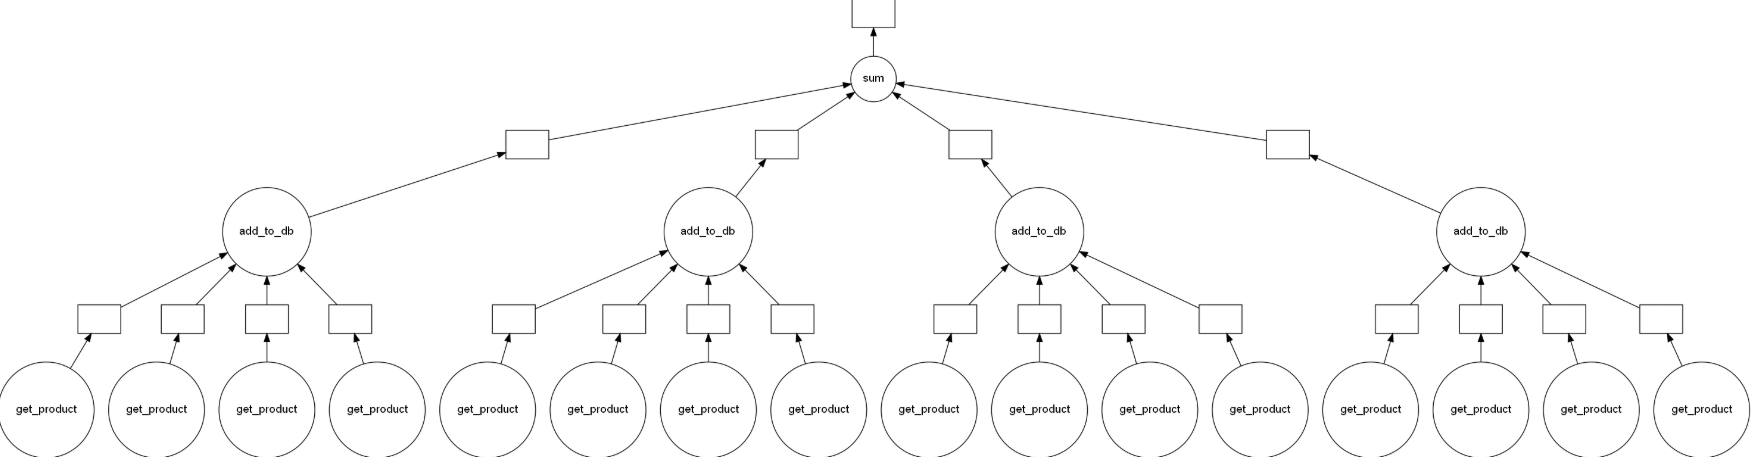![image.png](attachment:image.png)

Используя построенный граф, посчитайте общую сумму добавленных товаров и выведите ее на экран. Замерьте время выполнения данного решения.

В качестве демонстрации вставьте скриншот графа в процессе вычислений из дэшборда или результат работы метода `visualize`.

In [ ]:
import time
t1=time.time()
#Создайте отложенные версии функций get_product и add_to_db
get_product_delayed = dask.delayed(get_product)
add_to_db_delayed = dask.delayed(add_to_db)

#Постройте при помощи этих функций граф вычислений, который будет выглядеть следующим образом
prods = [get_product_delayed(pid) for pid in range(1,17)]
ttl = [add_to_db_delayed(*chunk) for chunk in [prods[i:i+4] for i in range(0, len(prods), 4)]]
sums = dask.delayed(sum)(ttl)
display(sums.visualize()) #В качестве демонстрации вставьте скриншот графа в процессе вычислений из дэшборда или результат работы метода visualize.

#посчитайте общую сумму добавленных товаров и выведите ее на экран. Замерьте время выполнения данного решения.
print(f"Общая сумма: {dask.compute(sums,scheduler='threads')[0]}")
print(f'\n\nВРЕМЯ ВЫПОЛНЕНИЯ: {time.time()-t1:.4f}\n\n')#Измерьте время выполнения кода.